# ENGE707 Kaggle Competition: Dataset Exploration

## Cat and Dog Facial Feature Classification

This notebook explores the supplied Kaggle dataset before any model is developed.

The notebook answers the following questions:

1. How are the training and test files organised?
2. How many images belong to each class?
3. Is the training dataset balanced?
4. What do images from each class look like?
5. Are the image dimensions and colour formats consistent?
6. Are any images unreadable or corrupted?
7. Are any images potentially blurry, unusually dark, or unusually bright?
8. Are there exact duplicate images?
9. Are any duplicate images assigned different labels?
10. How will the data be used for training, validation, and Kaggle submission?

This notebook does not train a model. PyTorch is therefore not required yet.

All random selections use a fixed seed so that the same results can be reproduced.

## 1. Import the Required Libraries

Only libraries needed for dataset exploration are imported.

- `Path` is used to work with folders and file paths.
- `ThreadPoolExecutor` helps inspect several images at the same time.
- `hashlib` creates a unique content code for each image. These codes help identify exact duplicates.
- `random` and `numpy` control random selections.
- `pandas` reads and analyses the CSV files.
- `matplotlib` creates graphs and displays images.
- `PIL` opens and inspects image files.
- `tqdm` displays progress bars during longer checks.

PyTorch is not imported because this notebook does not build or train a neural network.

In [1]:
# Imports the libraries used to explore the images and labels
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

## 2. Set the Random Seed and Dataset Paths

A random seed makes random operations repeatable.

For example, the representative-image figure should show the same images each time the notebook is run.

The following cell also finds the dataset folder. It works when the notebook is opened from either:

- the main project folder, or
- the `notebooks` folder.

In [2]:
# Sets the random seed and finds the original dataset folders
# Use the same seed throughout the project
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# The notebook may be running from the project folder or notebooks folder
possible_dataset_locations = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
]

DATASET_ROOT = next(
    (
        location
        for location in possible_dataset_locations
        if location.exists()
    ),
    None,
)

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "The dataset folder could not be found. "
        "Check where the notebook is saved and update DATASET_ROOT."
    )

TRAIN_IMAGE_DIR = DATASET_ROOT / "train" / "train"
TEST_IMAGE_DIR = DATASET_ROOT / "test" / "test"
TRAIN_LABELS_PATH = DATASET_ROOT / "train_labels.csv"
SAMPLE_SUBMISSION_PATH = DATASET_ROOT / "sample_submission.csv"

# Create folders for results produced by this notebook
PROJECT_ROOT = DATASET_ROOT.parent
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
QUALITY_DIR = PROJECT_ROOT / "outputs" / "quality_checks"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
QUALITY_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder:", DATASET_ROOT)
print("Training image folder:", TRAIN_IMAGE_DIR)
print("Test image folder:", TEST_IMAGE_DIR)
print("Figure output folder:", FIGURE_DIR)
print("Quality-check output folder:", QUALITY_DIR)

Dataset folder: /Users/fatehbhular/ENSE707-Kaggle-Competition/data
Training image folder: /Users/fatehbhular/ENSE707-Kaggle-Competition/data/train/train
Test image folder: /Users/fatehbhular/ENSE707-Kaggle-Competition/data/test/test
Figure output folder: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures
Quality-check output folder: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/quality_checks


## 3. Load the CSV Files

The dataset contains two CSV files:

- `train_labels.csv` provides the correct class for every training image.
- `sample_submission.csv` shows the required format and order for the Kaggle submission.

The `image_id` column is loaded as text. This is important because training IDs contain leading zeros, such as `00001`.

In [3]:
# Reads the training labels and sample submission into tables
train_labels = pd.read_csv(
    TRAIN_LABELS_PATH,
    dtype={"image_id": "string", "class": "string"},
)

sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": "string", "class": "string"},
)

print("Training-label shape:", train_labels.shape)
print("Sample-submission shape:", sample_submission.shape)

print("\nFirst five training labels:")
display(train_labels.head())

print("\nFirst five sample-submission rows:")
display(sample_submission.head())

Training-label shape: (63660, 2)
Sample-submission shape: (29443, 2)

First five training labels:


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose



First five sample-submission rows:


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth


## 4. Check the Dataset Structure

This section checks whether the CSV files and image folders agree.

The checks include:

- the number of training images;
- the number of test images;
- missing values in the CSV files;
- repeated image IDs;
- labels with no matching image;
- images with no matching label;
- unexpected class names; and
- unexpected file types.

These checks help find structural problems before image processing or model training begins.

In [4]:
# Checks that the expected classes and image files are present
OFFICIAL_CLASSES = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose",
]


def id_to_filename(image_id):
    """
    Convert an image ID into the five-digit JPG filename used by the dataset.

    Examples:
        1       -> 00001.jpg
        00001   -> 00001.jpg
    """
    image_stem = Path(str(image_id)).stem
    return f"{int(image_stem):05d}.jpg"


# Create the expected filename for every CSV row
train_labels["filename"] = train_labels["image_id"].apply(id_to_filename)
sample_submission["filename"] = sample_submission["image_id"].apply(
    id_to_filename
)

# Find all files in the image folders
train_folder_files = [
    path for path in TRAIN_IMAGE_DIR.iterdir() if path.is_file()
]

test_folder_files = [
    path for path in TEST_IMAGE_DIR.iterdir() if path.is_file()
]

# Keep the JPG files separately
train_image_files = sorted(
    path for path in train_folder_files if path.suffix.lower() == ".jpg"
)

test_image_files = sorted(
    path for path in test_folder_files if path.suffix.lower() == ".jpg"
)

unexpected_train_files = [
    path.name
    for path in train_folder_files
    if path.suffix.lower() != ".jpg"
]

unexpected_test_files = [
    path.name
    for path in test_folder_files
    if path.suffix.lower() != ".jpg"
]

# Compare the expected filenames with the actual filenames
expected_train_names = set(train_labels["filename"])
actual_train_names = {path.name for path in train_image_files}

expected_test_names = set(sample_submission["filename"])
actual_test_names = {path.name for path in test_image_files}

missing_train_images = sorted(
    expected_train_names - actual_train_names
)

training_images_without_labels = sorted(
    actual_train_names - expected_train_names
)

missing_test_images = sorted(
    expected_test_names - actual_test_names
)

test_images_not_in_submission = sorted(
    actual_test_names - expected_test_names
)

unexpected_classes = sorted(
    set(train_labels["class"].dropna()) - set(OFFICIAL_CLASSES)
)

structure_results = pd.DataFrame(
    {
        "Check": [
            "Training CSV rows",
            "Training JPG files",
            "Sample-submission rows",
            "Test JPG files",
            "Missing values in training CSV",
            "Repeated training IDs",
            "Repeated submission IDs",
            "Training labels without images",
            "Training images without labels",
            "Submission IDs without test images",
            "Test images not in submission",
            "Unexpected training file types",
            "Unexpected test file types",
            "Unexpected class names",
        ],
        "Result": [
            len(train_labels),
            len(train_image_files),
            len(sample_submission),
            len(test_image_files),
            int(train_labels.isna().sum().sum()),
            int(train_labels["image_id"].duplicated().sum()),
            int(sample_submission["image_id"].duplicated().sum()),
            len(missing_train_images),
            len(training_images_without_labels),
            len(missing_test_images),
            len(test_images_not_in_submission),
            len(unexpected_train_files),
            len(unexpected_test_files),
            len(unexpected_classes),
        ],
    }
)

display(structure_results)

# Saves the table as a CSV file for later notebooks or report evidence
structure_results.to_csv(
    QUALITY_DIR / "dataset_structure_checks.csv",
    index=False,
)

,Check,Result
0,Training CSV rows,63660
1,Training JPG files,63660
2,Sample-submission rows,29443
3,Test JPG files,29443
4,Missing values in training CSV,0
5,Repeated training IDs,0
6,Repeated submission IDs,0
7,Training labels without images,0
8,Training images without labels,0
9,Submission IDs without test images,0


### Interpretation of the Dataset Structure

The output above should be used to answer the following questions in the report:

- How many labelled training images are available?
- How many unlabelled test images are available?
- Does every training label have a matching image?
- Does every training image have a label?
- Does every sample-submission ID have a matching test image?
- Are any IDs repeated?
- Are any values missing?
- Are all class names valid?
- Are there unexpected file types?

A result of zero is expected for missing files, duplicate IDs, missing values, and unexpected classes. However, this should only be stated after the code has been run.

## 5. Count the Images in Each Class

This section counts the number of labelled training images in every class.

The counts and percentages help determine whether the training dataset is balanced.

In [5]:
# Counts the images and calculates the percentage in each class
class_distribution = (
    train_labels["class"]
    .value_counts()
    .reindex(OFFICIAL_CLASSES)
    .rename_axis("Class")
    .reset_index(name="Images")
)

class_distribution["Percentage"] = (
    class_distribution["Images"]
    / class_distribution["Images"].sum()
    * 100
).round(2)

display(class_distribution)

print(
    "Total labelled training images:",
    class_distribution["Images"].sum(),
)

# Saves the table as a CSV file for later notebooks or report evidence
class_distribution.to_csv(
    QUALITY_DIR / "class_distribution.csv",
    index=False,
)

,Class,Images,Percentage
0,CatEye,13884,21.81
1,DogEye,11580,18.19
2,CatFace,6942,10.9
3,DogFace,5790,9.1
4,CatMouth,6942,10.9
5,DogMouth,5790,9.1
6,CatNose,6942,10.9
7,DogNose,5790,9.1


Total labelled training images: 63660


## 6. Plot the Class Distribution

The following bar graph makes the differences between class sizes easier to see.

The number above each bar shows:

- the number of images; and
- the percentage of the complete labelled training dataset.

The figure is saved automatically so that it can be inserted into the report.

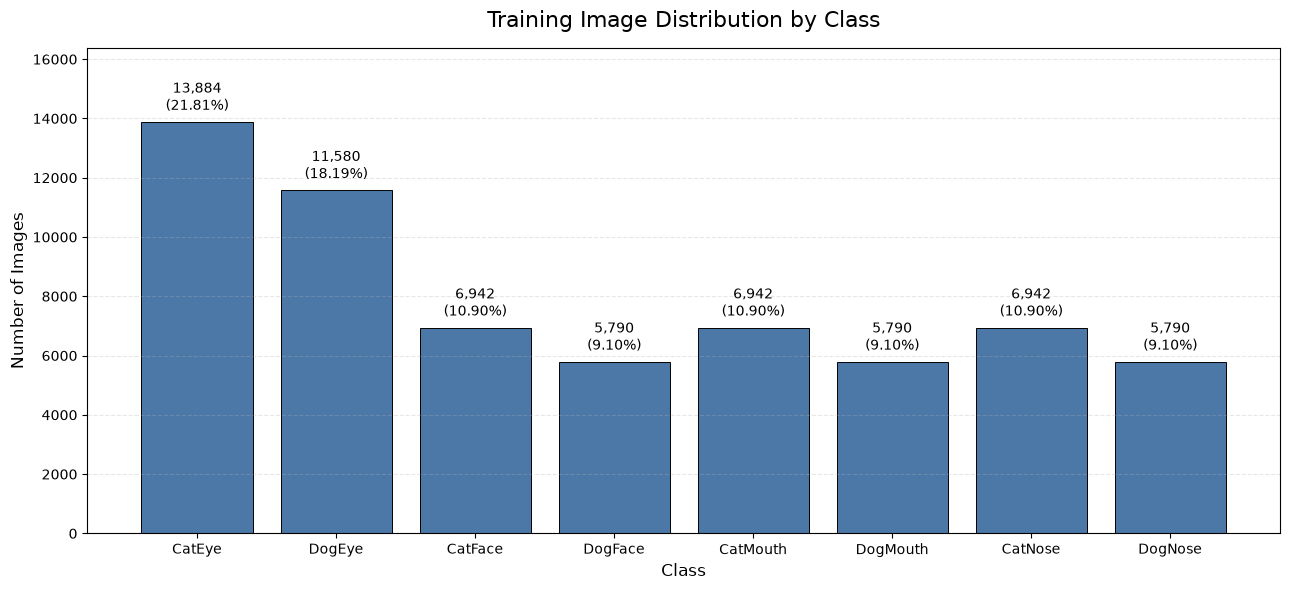

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_01_class_distribution.png


In [6]:
# Draws and saves a chart of the training class counts
fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    class_distribution["Class"],
    class_distribution["Images"],
    color="#4C78A8",
    edgecolor="black",
    linewidth=0.7,
)

ax.set_title(
    "Training Image Distribution by Class",
    fontsize=16,
    pad=15,
)

ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Number of Images", fontsize=12)
ax.set_ylim(0, class_distribution["Images"].max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, images, percentage in zip(
    bars,
    class_distribution["Images"],
    class_distribution["Percentage"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 250,
        f"{images:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.xticks(rotation=0)
plt.tight_layout()

figure_path = FIGURE_DIR / "figure_01_class_distribution.png"
# Saves the figure so it can be included in the report
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)

### Discussion of Class Balance

Use the table and graph to explain the following points:

- The eight classes do not contain the same number of images.
- `CatEye` and `DogEye` are the two largest classes.
- Each eye class contains twice as many images as the matching face, mouth, or nose class.
- Each cat class contains more images than the matching dog class.
- The dataset is therefore not fully balanced across the eight classes.
- The imbalance is systematic rather than random.
- A stratified training-validation split will be needed so both subsets contain similar percentages of every class.
- Class-level precision, recall, and F1-score should later be reported because overall accuracy may hide weak performance in smaller classes.

Do not describe the dataset as perfectly balanced.

## 7. Display Representative Images from Every Class

This section displays randomly selected images from all eight classes.

A fixed random seed is used. This means the same images will be selected each time the notebook is run.

The figure helps examine:

- differences between the eight classes;
- variation within the same class;
- image crop sizes;
- lighting and background differences;
- possible blur;
- and classes that may be visually difficult to separate.

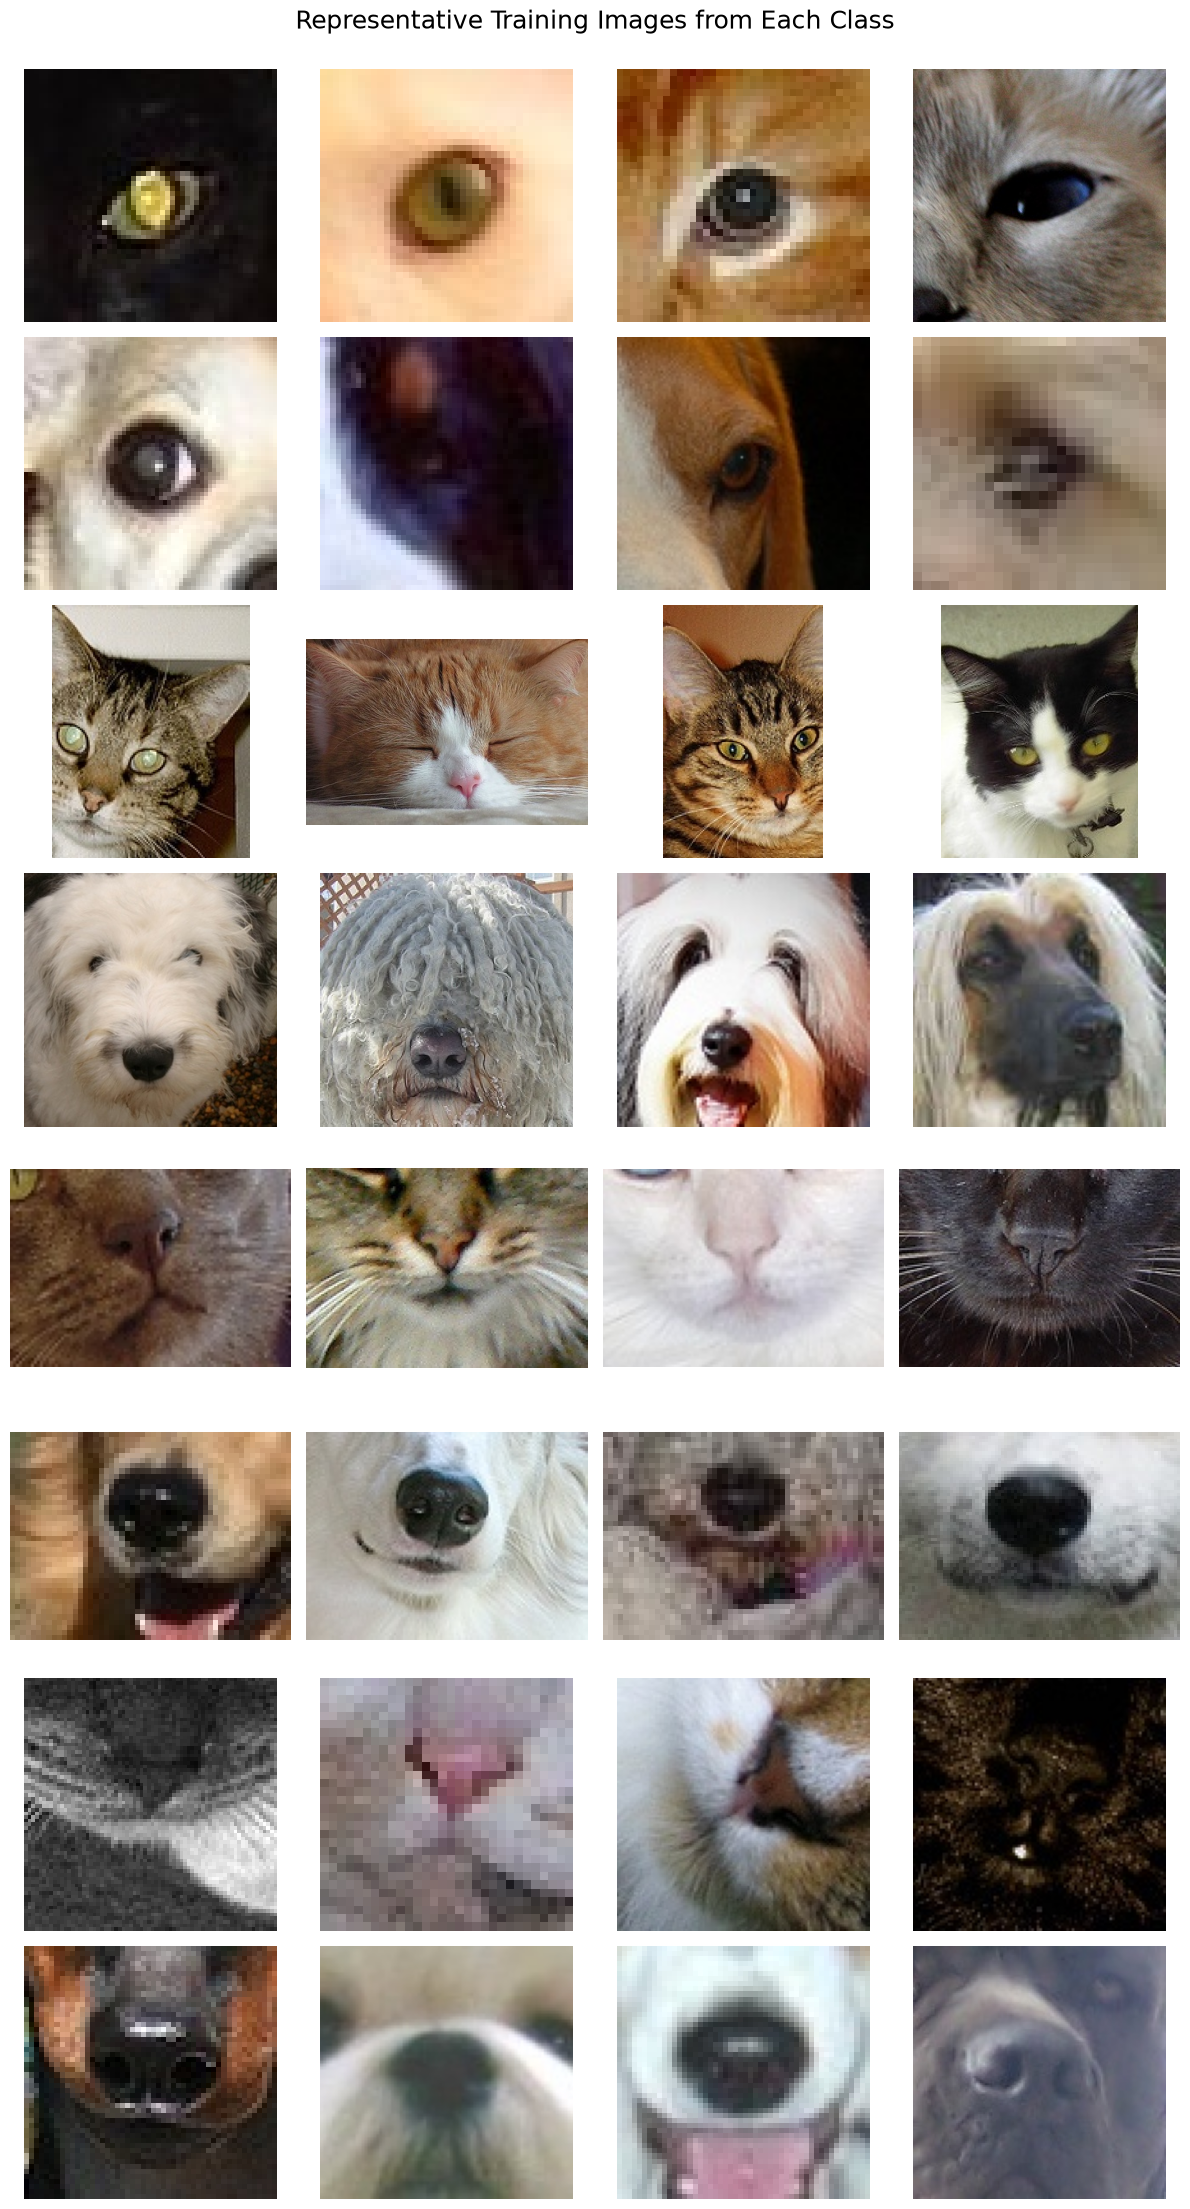

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_02_representative_images.png


In [7]:
# Shows a repeatable sample of training images from each class
SAMPLES_PER_CLASS = 4

fig, axes = plt.subplots(
    nrows=len(OFFICIAL_CLASSES),
    ncols=SAMPLES_PER_CLASS,
    figsize=(12, 22),
)

for row_number, class_name in enumerate(OFFICIAL_CLASSES):
    class_rows = train_labels[
        train_labels["class"] == class_name
    ]

    selected_rows = class_rows.sample(
        n=SAMPLES_PER_CLASS,
        random_state=RANDOM_SEED,
    )

    for column_number, (_, selected_row) in enumerate(
        selected_rows.iterrows()
    ):
        image_path = TRAIN_IMAGE_DIR / selected_row["filename"]

        with Image.open(image_path) as image:
            displayed_image = image.convert("RGB")

        axis = axes[row_number, column_number]
        axis.imshow(displayed_image)
        axis.axis("off")

        if column_number == 0:
            axis.set_ylabel(
                class_name,
                fontsize=12,
                fontweight="bold",
                rotation=0,
                labelpad=45,
                va="center",
            )

fig.suptitle(
    "Representative Training Images from Each Class",
    fontsize=18,
    y=1.002,
)

plt.tight_layout()

sample_figure_path = (
    FIGURE_DIR / "figure_02_representative_images.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    sample_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", sample_figure_path)

## 8. Inspect Image Properties and File Quality

Every training and test image will now be opened and inspected.

For each image, the code records:

- whether it can be opened;
- its width and height;
- its colour format;
- its brightness;
- and a simple sharpness score.

The sharpness score measures changes between nearby pixels. Images with fewer visible edges usually receive lower scores.

A low score does not prove that an image is blurry. For example, a clear image with a plain background may also receive a low score. Therefore, low-scoring images will be displayed for manual review.

In [8]:
# Reads image properties and records files that cannot be opened
def inspect_image(image_path, dataset_split):
    """
    Open one image and record its basic properties.

    A returned error means that the image could not be read successfully.
    """
    try:
        with Image.open(image_path) as image:
            image.load()

            width, height = image.size
            colour_mode = image.mode
            image_format = image.format

            # Convert to a small grayscale image for fast quality estimates
            grayscale_image = image.convert("L").resize((128, 128))
            grayscale_array = np.asarray(
                grayscale_image,
                dtype=np.float32,
            )

        # Brightness ranges approximately from 0 (black) to 255 (white)
        brightness = float(grayscale_array.mean())

        # Estimate edge detail using differences between nearby pixels
        horizontal_changes = np.diff(grayscale_array, axis=1)
        vertical_changes = np.diff(grayscale_array, axis=0)

        sharpness_score = float(
            np.var(horizontal_changes)
            + np.var(vertical_changes)
        )

        return {
            "split": dataset_split,
            "filename": image_path.name,
            "path": str(image_path),
            "readable": True,
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 4),
            "colour_mode": colour_mode,
            "image_format": image_format,
            "brightness": round(brightness, 2),
            "sharpness_score": round(sharpness_score, 2),
            "error": None,
        }

    except Exception as error:
        return {
            "split": dataset_split,
            "filename": image_path.name,
            "path": str(image_path),
            "readable": False,
            "width": np.nan,
            "height": np.nan,
            "aspect_ratio": np.nan,
            "colour_mode": None,
            "image_format": None,
            "brightness": np.nan,
            "sharpness_score": np.nan,
            "error": str(error),
        }


def inspect_image_item(item):
    """Allow the inspection function to be used by ThreadPoolExecutor."""
    image_path, dataset_split = item
    return inspect_image(image_path, dataset_split)


images_to_inspect = (
    [(path, "train") for path in train_image_files]
    + [(path, "test") for path in test_image_files]
)

print(f"Images to inspect: {len(images_to_inspect):,}")

# Several images are inspected at once to reduce waiting time
with ThreadPoolExecutor(max_workers=8) as executor:
    inspection_results = list(
        tqdm(
            executor.map(inspect_image_item, images_to_inspect),
            total=len(images_to_inspect),
            desc="Inspecting images",
        )
    )

image_properties = pd.DataFrame(inspection_results)

# Saves the table as a CSV file for later notebooks or report evidence
image_properties.to_csv(
    QUALITY_DIR / "image_properties.csv",
    index=False,
)

print("Inspection complete.")
display(image_properties.head())

Images to inspect: 93,103


Inspecting images:   0%|          | 0/93103 [00:00<?, ?it/s]

Inspection complete.


,split,filename,path,readable,width,height,aspect_ratio,colour_mode,image_format,brightness,sharpness_score,error
0,train,00001.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,True,36,36,1.0000,RGB,JPEG,122.09,69.18,None
1,train,00002.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,True,214,157,1.3631,RGB,JPEG,128.12,829.58,None
2,train,00003.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,True,97,97,1.0000,RGB,JPEG,124.02,412.59,None
3,train,00004.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,True,110,110,1.0000,RGB,JPEG,98.98,80.85,None
4,train,00005.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,True,42,42,1.0000,RGB,JPEG,87.99,39.02,None


## 9. Check for Unreadable or Corrupted Images

An unreadable image may interrupt model training.

The following cell reports how many files could and could not be opened. It also displays the names and error messages for any unreadable files.

In [9]:
# Summarises files that were read successfully or could not be opened
readability_summary = (
    image_properties
    .groupby(["split", "readable"])
    .size()
    .rename("images")
    .reset_index()
)

display(readability_summary)

unreadable_images = image_properties[
    image_properties["readable"] == False
].copy()

print(f"Unreadable images: {len(unreadable_images):,}")

if len(unreadable_images) > 0:
    display(
        unreadable_images[
            ["split", "filename", "error"]
        ]
    )
else:
    print("Every image was opened successfully.")

# Saves the table as a CSV file for later notebooks or report evidence
unreadable_images.to_csv(
    QUALITY_DIR / "unreadable_images.csv",
    index=False,
)

,split,readable,images
0,test,True,29443
1,train,True,63660


Unreadable images: 0
Every image was opened successfully.


## 10. Examine Image Dimensions

A model processes images in groups. Images in the same group must have matching dimensions.

This section checks:

- the smallest and largest image widths;
- the smallest and largest image heights;
- the number of different image sizes;
- and the most common image dimensions.

If the dimensions are inconsistent, the preprocessing pipeline will need to resize every image to a fixed size.

In [10]:
# Summarises the widths and heights of readable images
readable_properties = image_properties[
    image_properties["readable"] == True
].copy()

dimension_summary = (
    readable_properties
    .groupby("split")
    .agg(
        images=("filename", "count"),
        minimum_width=("width", "min"),
        maximum_width=("width", "max"),
        median_width=("width", "median"),
        minimum_height=("height", "min"),
        maximum_height=("height", "max"),
        median_height=("height", "median"),
    )
    .reset_index()
)

display(dimension_summary)

unique_dimensions = (
    readable_properties
    .groupby("split")
    .apply(
        lambda group: group[
            ["width", "height"]
        ].drop_duplicates().shape[0],
        include_groups=False,
    )
    .rename("unique_width_height_combinations")
    .reset_index()
)

display(unique_dimensions)

most_common_dimensions = (
    readable_properties
    .groupby(["split", "width", "height"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values(
        ["split", "images"],
        ascending=[True, False],
    )
    .groupby("split")
    .head(10)
)

display(most_common_dimensions)

# Saves the table as a CSV file for later notebooks or report evidence
dimension_summary.to_csv(
    QUALITY_DIR / "dimension_summary.csv",
    index=False,
)

# Saves the table as a CSV file for later notebooks or report evidence
most_common_dimensions.to_csv(
    QUALITY_DIR / "most_common_dimensions.csv",
    index=False,
)

,split,images,minimum_width,maximum_width,median_width,minimum_height,maximum_height,median_height
0,test,29443,8,1832,82.0,9,1978,80.0
1,train,63660,4,2219,84.0,4,2219,80.0


,split,unique_width_height_combinations
0,test,7786
1,train,7861


,split,width,height,images
379,test,40,40,503
640,test,50,50,402
1581,test,80,80,370
181,test,30,30,349
924,test,60,60,343
1246,test,70,70,260
1053,test,64,64,185
633,test,50,40,177
987,test,62,62,162
1934,test,90,90,162


## 11. Plot the Image Dimensions

The scatter plot shows the width and height of the images.

A random sample is used in the graph so that a very large number of overlapping points does not make the figure unreadable. The summary tables above still use every readable image.

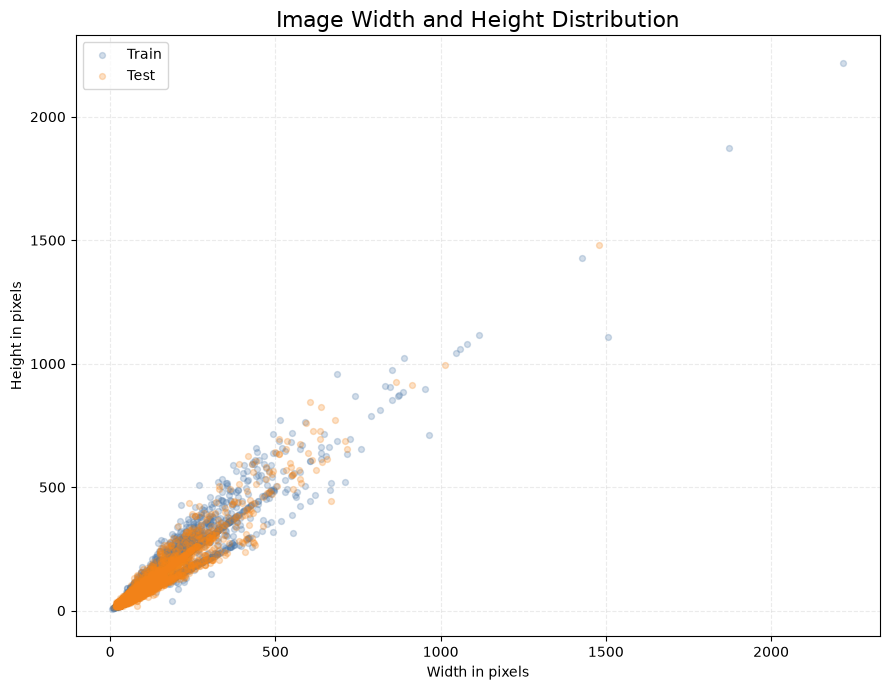

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_03_image_dimensions.png


In [11]:
# Plots image widths and heights to show differences in size
plot_sample_size = min(10_000, len(readable_properties))

dimension_plot_data = readable_properties.sample(
    n=plot_sample_size,
    random_state=RANDOM_SEED,
)

fig, ax = plt.subplots(figsize=(9, 7))

for split_name, colour in [
    ("train", "#4C78A8"),
    ("test", "#F58518"),
]:
    split_data = dimension_plot_data[
        dimension_plot_data["split"] == split_name
    ]

    ax.scatter(
        split_data["width"],
        split_data["height"],
        label=split_name.title(),
        alpha=0.25,
        s=18,
        color=colour,
    )

ax.set_title("Image Width and Height Distribution", fontsize=16)
ax.set_xlabel("Width in pixels")
ax.set_ylabel("Height in pixels")
ax.grid(True, linestyle="--", alpha=0.25)
ax.legend()

plt.tight_layout()

dimension_figure_path = (
    FIGURE_DIR / "figure_03_image_dimensions.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    dimension_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Figure saved to:", dimension_figure_path)

## 12. Check Image Colour Formats

Most pretrained image models expect three colour channels:

- red;
- green; and
- blue.

These images use the `RGB` colour format.

A dataset may also contain grayscale or transparent images. The following cell counts every colour format found in the training and test folders.

If different formats are present, the preprocessing pipeline can convert every image to RGB.

In [12]:
# Counts the colour formats found in the readable images
colour_mode_summary = (
    readable_properties
    .groupby(["split", "colour_mode"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values(["split", "images"], ascending=[True, False])
)

display(colour_mode_summary)

# Saves the table as a CSV file for later notebooks or report evidence
colour_mode_summary.to_csv(
    QUALITY_DIR / "colour_mode_summary.csv",
    index=False,
)

,split,colour_mode,images
0,test,RGB,29443
1,train,RGB,63660


## 13. Review Potentially Blurry Images

The images with the lowest sharpness scores are displayed below.

These images are only possible blur candidates. They should be inspected manually before being described as blurry.

The code does not delete any image.

,split,filename,width,height,sharpness_score
12117,train,12118.jpg,16,16,0.25
44793,train,44794.jpg,26,18,0.35
81976,test,18317.jpg,30,20,0.38
14668,train,14669.jpg,30,30,0.43
86824,test,23165.jpg,31,20,0.46
37906,train,37907.jpg,16,16,0.52
34013,train,34014.jpg,50,50,0.59
32163,train,32164.jpg,16,16,0.61
35820,train,35821.jpg,16,16,0.64
62252,train,62253.jpg,10,10,0.68


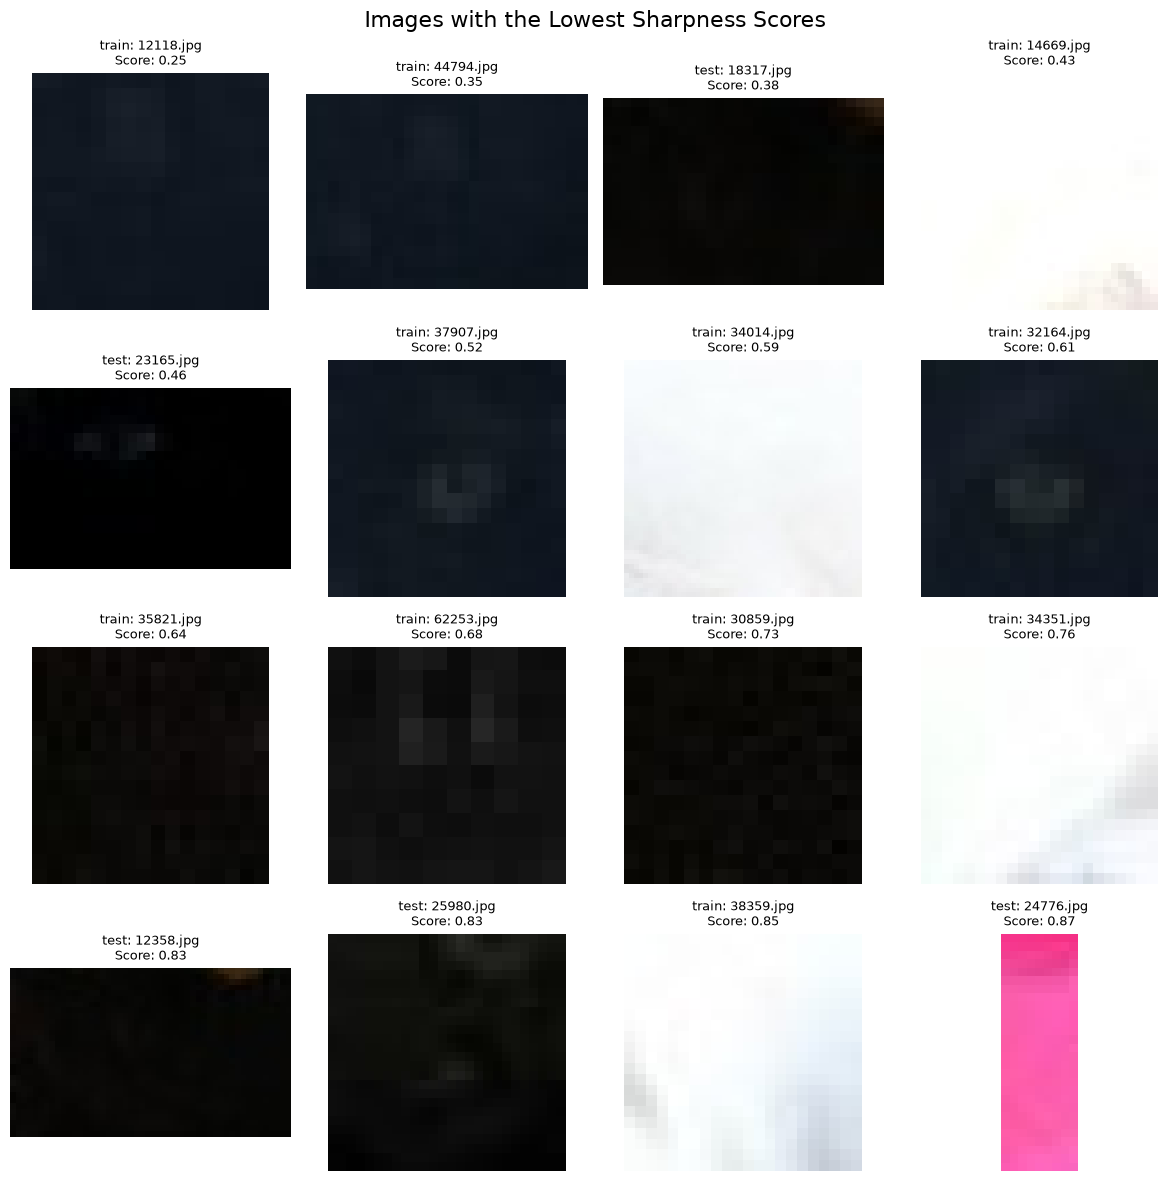

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_04_blur_candidates.png


In [13]:
# Shows training images with low sharpness scores for review
NUMBER_OF_BLUR_CANDIDATES = 16

blur_candidates = (
    readable_properties
    .sort_values("sharpness_score")
    .head(NUMBER_OF_BLUR_CANDIDATES)
    .copy()
)

display(
    blur_candidates[
        [
            "split",
            "filename",
            "width",
            "height",
            "sharpness_score",
        ]
    ]
)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for axis, (_, row) in zip(axes, blur_candidates.iterrows()):
    with Image.open(row["path"]) as image:
        displayed_image = image.convert("RGB")

    axis.imshow(displayed_image)
    axis.set_title(
        f"{row['split']}: {row['filename']}\n"
        f"Score: {row['sharpness_score']:.2f}",
        fontsize=9,
    )
    axis.axis("off")

plt.suptitle(
    "Images with the Lowest Sharpness Scores",
    fontsize=16,
)

plt.tight_layout()

blur_figure_path = (
    FIGURE_DIR / "figure_04_blur_candidates.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    blur_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Saves the table as a CSV file for later notebooks or report evidence
blur_candidates.to_csv(
    QUALITY_DIR / "blur_candidates.csv",
    index=False,
)

print("Figure saved to:", blur_figure_path)

## 14. Review Unusually Dark and Bright Images

Brightness is measured on a scale that is approximately:

- `0` for completely black;
- `255` for completely white.

The darkest and brightest images are displayed for manual inspection.

These images are not automatically treated as poor-quality data.

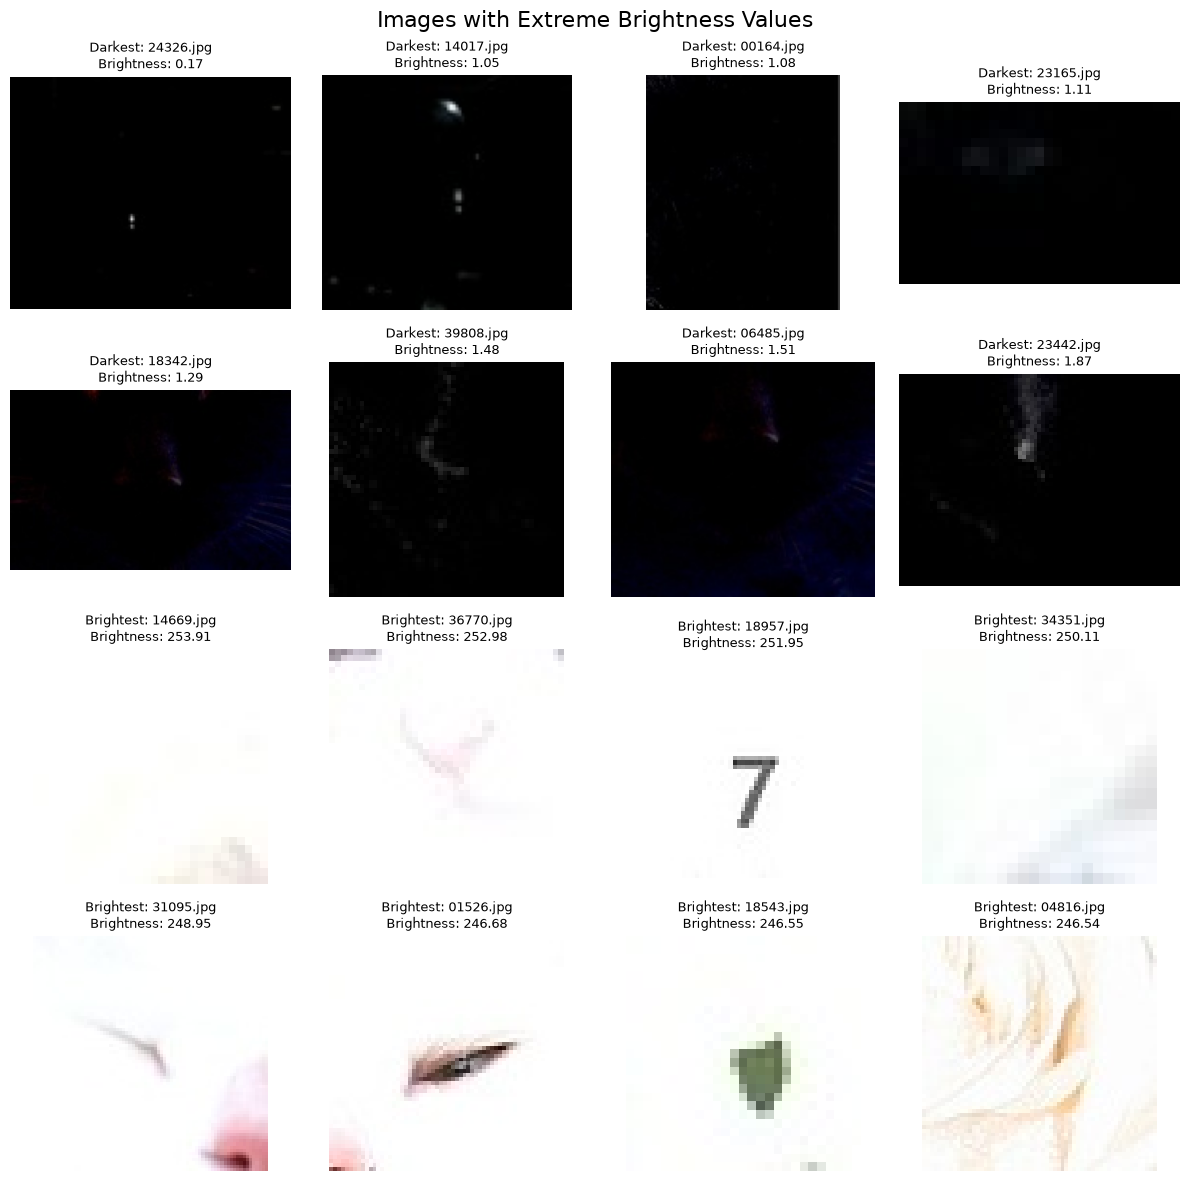

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_05_brightness_examples.png


In [14]:
# Shows unusually dark and bright training images for review
NUMBER_OF_BRIGHTNESS_EXAMPLES = 8

darkest_images = (
    readable_properties
    .sort_values("brightness")
    .head(NUMBER_OF_BRIGHTNESS_EXAMPLES)
)

brightest_images = (
    readable_properties
    .sort_values("brightness", ascending=False)
    .head(NUMBER_OF_BRIGHTNESS_EXAMPLES)
)

brightness_examples = pd.concat(
    [
        darkest_images.assign(review_group="Darkest"),
        brightest_images.assign(review_group="Brightest"),
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for axis, (_, row) in zip(
    axes,
    brightness_examples.iterrows(),
):
    with Image.open(row["path"]) as image:
        displayed_image = image.convert("RGB")

    axis.imshow(displayed_image)
    axis.set_title(
        f"{row['review_group']}: {row['filename']}\n"
        f"Brightness: {row['brightness']:.2f}",
        fontsize=9,
    )
    axis.axis("off")

plt.suptitle(
    "Images with Extreme Brightness Values",
    fontsize=16,
)

plt.tight_layout()

brightness_figure_path = (
    FIGURE_DIR / "figure_05_brightness_examples.png"
)

# Saves the figure so it can be included in the report
plt.savefig(
    brightness_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Saves the table as a CSV file for later notebooks or report evidence
brightness_examples.to_csv(
    QUALITY_DIR / "brightness_examples.csv",
    index=False,
)

print("Figure saved to:", brightness_figure_path)

## 15. Find Exact Duplicate Images

An exact duplicate has exactly the same file contents as another image.

The code creates a SHA-256 hash for every readable image. A hash is a long code calculated from the file contents. Files with the same SHA-256 hash are exact copies.

Duplicate checks are important because:

- repeated images may give some examples more influence during training;
- identical images could have conflicting labels; and
- a copy in training and another copy in validation could make validation accuracy misleading.

This check finds exact copies. It does not find resized, compressed, edited, or differently cropped versions of the same photograph.

In [15]:
# Compares file hashes to find images with identical file contents
def calculate_sha256(file_path):
    """Calculate a SHA-256 content hash for one file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as image_file:
        while True:
            file_chunk = image_file.read(1024 * 1024)

            if not file_chunk:
                break

            sha256.update(file_chunk)

    return sha256.hexdigest()


readable_paths = [
    Path(path)
    for path in readable_properties["path"]
]

with ThreadPoolExecutor(max_workers=8) as executor:
    sha256_hashes = list(
        tqdm(
            executor.map(calculate_sha256, readable_paths),
            total=len(readable_paths),
            desc="Hashing images",
        )
    )

image_hashes = readable_properties[
    ["split", "filename", "path"]
].copy()

image_hashes["sha256"] = sha256_hashes

# Keep every row whose hash appears more than once
exact_duplicates = image_hashes[
    image_hashes["sha256"].duplicated(keep=False)
].copy()

exact_duplicates = exact_duplicates.sort_values(
    ["sha256", "split", "filename"]
)

exact_duplicate_group_count = (
    exact_duplicates["sha256"].nunique()
)

exact_duplicate_extra_files = (
    len(exact_duplicates) - exact_duplicate_group_count
)

print(
    "Exact duplicate groups:",
    f"{exact_duplicate_group_count:,}",
)

print(
    "Additional duplicate files:",
    f"{exact_duplicate_extra_files:,}",
)

# Saves the table as a CSV file for later notebooks or report evidence
exact_duplicates.to_csv(
    QUALITY_DIR / "exact_duplicate_images.csv",
    index=False,
)

display(exact_duplicates.head(20))

Hashing images:   0%|          | 0/93103 [00:00<?, ?it/s]

Exact duplicate groups: 77
Additional duplicate files: 77


,split,filename,path,sha256
67256,test,03597.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,018943b207152141707aec0e74b5eec70066d3616c59d1...
69200,test,05541.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,018943b207152141707aec0e74b5eec70066d3616c59d1...
74114,test,10455.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,01dd0330f9c599090b6fa4e015d258f0451c2c147cdf17...
85294,test,21635.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,01dd0330f9c599090b6fa4e015d258f0451c2c147cdf17...
64540,test,00881.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,03997e5e3c699a8a6464cd8dc4d106dff6074fea81f1c9...
80863,test,17204.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,03997e5e3c699a8a6464cd8dc4d106dff6074fea81f1c9...
73232,test,09573.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,0628d83766683d3a332e91660e30145962977ce4a503f9...
87326,test,23667.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,0628d83766683d3a332e91660e30145962977ce4a503f9...
64290,test,00631.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,0d79bcdb2ef3a348447d0097afdf0bd2266ba26a960337...
92138,test,28479.jpg,/Users/fatehbhular/ENSE707-Kaggle-Competition/...,0d79bcdb2ef3a348447d0097afdf0bd2266ba26a960337...


## 16. Check Duplicate Labels and Train-Test Overlap

Duplicate images require further investigation.

This section checks:

1. Whether exact training duplicates have different class labels.
2. Whether an exact image appears in both the training and test folders.

A duplicate group with different training labels may indicate a label conflict.

An exact match between training and test images should be reported. However, the hidden test label must not be manually assigned or changed.

In [16]:
# Checks duplicate labels and exact matches between dataset folders
# Connect training duplicate filenames to their known class labels
filename_to_class = train_labels.set_index("filename")["class"]

training_duplicate_rows = exact_duplicates[
    exact_duplicates["split"] == "train"
].copy()

training_duplicate_rows["class"] = (
    training_duplicate_rows["filename"]
    .map(filename_to_class)
)

labels_per_duplicate_group = (
    training_duplicate_rows
    .groupby("sha256")["class"]
    .nunique()
)

conflicting_hashes = labels_per_duplicate_group[
    labels_per_duplicate_group > 1
].index

conflicting_label_duplicates = training_duplicate_rows[
    training_duplicate_rows["sha256"].isin(conflicting_hashes)
].copy()

# Find hashes that appear in both training and test folders
splits_per_hash = (
    exact_duplicates
    .groupby("sha256")["split"]
    .nunique()
)

train_test_overlap_hashes = splits_per_hash[
    splits_per_hash > 1
].index

train_test_exact_matches = exact_duplicates[
    exact_duplicates["sha256"].isin(train_test_overlap_hashes)
].copy()

duplicate_summary = pd.DataFrame(
    {
        "Check": [
            "Exact duplicate groups",
            "Additional exact duplicate files",
            "Duplicate groups with conflicting training labels",
            "Exact duplicate groups shared by train and test",
        ],
        "Result": [
            exact_duplicate_group_count,
            exact_duplicate_extra_files,
            len(conflicting_hashes),
            len(train_test_overlap_hashes),
        ],
    }
)

display(duplicate_summary)

print("\nTraining duplicates with different labels:")
display(conflicting_label_duplicates.head(20))

print("\nExact matches across training and test folders:")
display(train_test_exact_matches.head(20))

# Saves the table as a CSV file for later notebooks or report evidence
conflicting_label_duplicates.to_csv(
    QUALITY_DIR / "duplicate_label_conflicts.csv",
    index=False,
)

# Saves the table as a CSV file for later notebooks or report evidence
train_test_exact_matches.to_csv(
    QUALITY_DIR / "train_test_exact_matches.csv",
    index=False,
)

,Check,Result
0,Exact duplicate groups,77
1,Additional exact duplicate files,77
2,Duplicate groups with conflicting training labels,0
3,Exact duplicate groups shared by train and test,0



Training duplicates with different labels:


,split,filename,path,sha256,class



Exact matches across training and test folders:


,split,filename,path,sha256


## 17. Display Examples of Exact Duplicate Groups

The following code displays a small number of duplicate groups.

This visual check helps confirm that the hash-based results are genuine duplicates and shows whether the files use different names or labels.

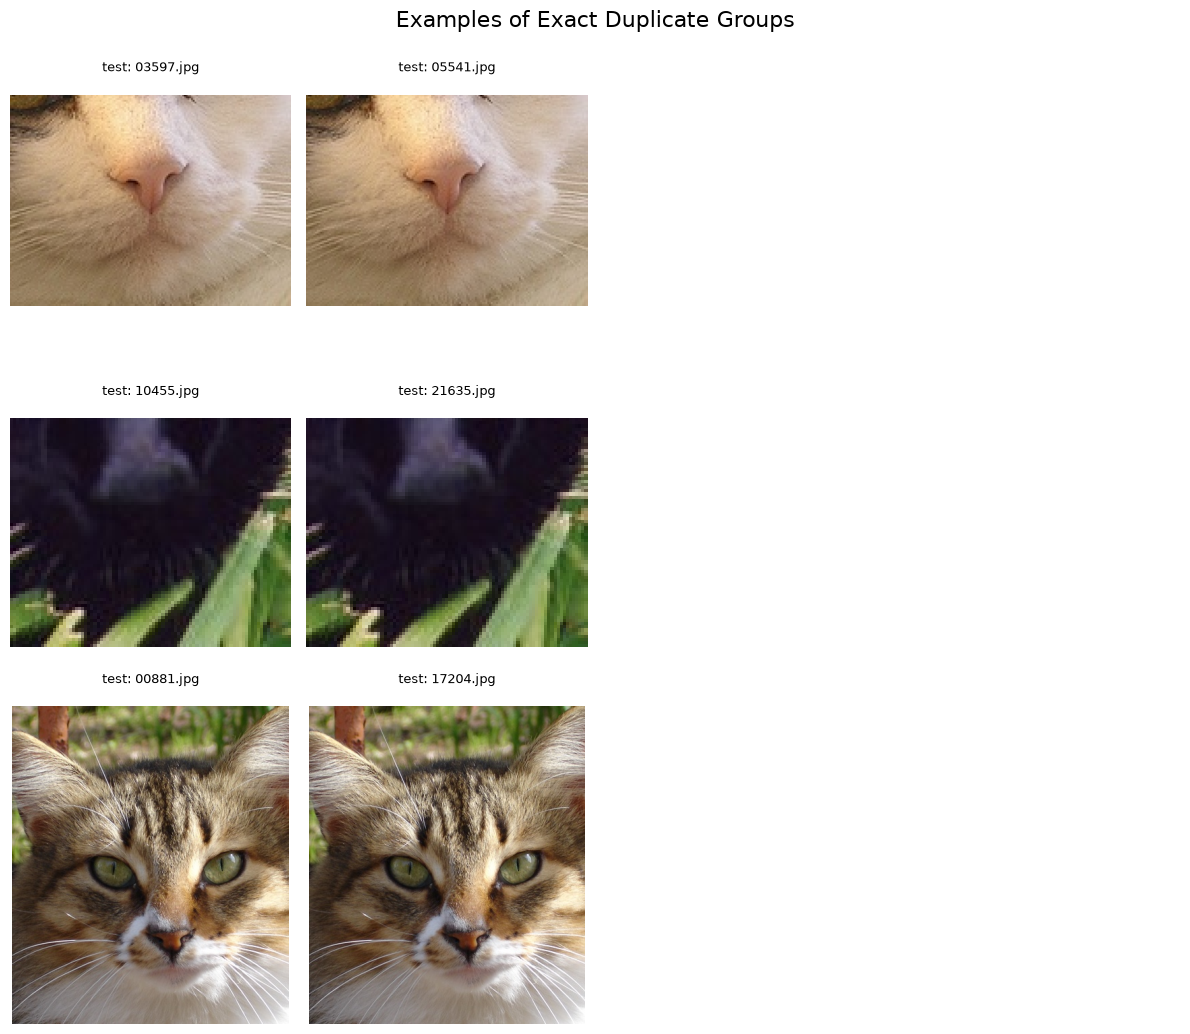

Figure saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_06_exact_duplicates.png


In [17]:
# Shows examples of files belonging to the same duplicate group
MAXIMUM_GROUPS_TO_DISPLAY = 3
MAXIMUM_IMAGES_PER_GROUP = 4

duplicate_hashes_to_display = (
    exact_duplicates["sha256"]
    .drop_duplicates()
    .head(MAXIMUM_GROUPS_TO_DISPLAY)
    .tolist()
)

if len(duplicate_hashes_to_display) == 0:
    print("No exact duplicate groups were found.")

else:
    fig, axes = plt.subplots(
        nrows=len(duplicate_hashes_to_display),
        ncols=MAXIMUM_IMAGES_PER_GROUP,
        figsize=(12, 3.5 * len(duplicate_hashes_to_display)),
        squeeze=False,
    )

    for row_number, duplicate_hash in enumerate(
        duplicate_hashes_to_display
    ):
        duplicate_group = exact_duplicates[
            exact_duplicates["sha256"] == duplicate_hash
        ].head(MAXIMUM_IMAGES_PER_GROUP)

        for column_number in range(MAXIMUM_IMAGES_PER_GROUP):
            axis = axes[row_number, column_number]
            axis.axis("off")

            if column_number >= len(duplicate_group):
                continue

            duplicate_row = duplicate_group.iloc[column_number]

            with Image.open(duplicate_row["path"]) as image:
                displayed_image = image.convert("RGB")

            image_class = ""

            if duplicate_row["split"] == "train":
                image_class = filename_to_class.get(
                    duplicate_row["filename"],
                    "",
                )

            axis.imshow(displayed_image)
            axis.set_title(
                f"{duplicate_row['split']}: "
                f"{duplicate_row['filename']}\n"
                f"{image_class}",
                fontsize=9,
            )

    plt.suptitle("Examples of Exact Duplicate Groups", fontsize=16)
    plt.tight_layout()

    duplicate_figure_path = (
        FIGURE_DIR / "figure_06_exact_duplicates.png"
    )

    # Saves the figure so it can be included in the report
    plt.savefig(
        duplicate_figure_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print("Figure saved to:", duplicate_figure_path)

## 18. Review Unclear Class Boundaries

Some images may be difficult to classify even when the file itself is valid.

Possible reasons include:

- the image is tightly cropped;
- the species is not visually clear;
- the mouth and nose appear in the same crop;
- the image is dark or blurry;
- or the complete face is only partly visible.

There is no automatic test that can prove that a class boundary is unclear. This must be discussed using the representative images, low-sharpness images, brightness examples, duplicate conflicts, and later model errors.

Record observations carefully. An image that is difficult to understand should not automatically be described as incorrectly labelled.

## 19. Explain How the Dataset Will Be Used

The competition provides two main image groups.

### Labelled training images

The 63,660 labelled images will be used for model development.

After the duplicate analysis is complete, these images will be divided into:

- a training subset; and
- a validation subset.

The training subset will teach the model. The validation subset will check how well the model performs on images that were not used to update its weights.

An 80/20 split is planned. The split will keep similar class percentages in both subsets.

If exact duplicate groups are found, all copies from the same group should remain in one subset. This prevents the model from seeing one copy during training and an identical copy during validation.

### Unlabelled test images

The 29,443 test images will not be used to train, compare, or adjust models.

They will only be used after the final model and training settings have been chosen. The final model will predict one class for each test image, and the predictions will be written to a CSV file using the order required by `sample_submission.csv`.

The hidden test labels are controlled by Kaggle and are used to calculate the competition accuracy.

## 20. Create a Data-Quality Summary

The final table combines the most important results from this notebook.

It will be saved as a CSV file and can be adapted for the report.

The table separates confirmed results from checks that still require human judgement.

In [18]:
# Saves a summary of the dataset quality checks
training_properties = readable_properties[
    readable_properties["split"] == "train"
]

test_properties = readable_properties[
    readable_properties["split"] == "test"
]

data_quality_summary = pd.DataFrame(
    {
        "Quality check": [
            "Training images",
            "Test images",
            "Missing training images",
            "Training images without labels",
            "Missing test images",
            "Repeated training IDs",
            "Missing training CSV values",
            "Unreadable images",
            "Unique training image dimensions",
            "Unique test image dimensions",
            "Training colour formats",
            "Test colour formats",
            "Exact duplicate groups",
            "Duplicate groups with conflicting labels",
            "Exact train-test duplicate groups",
            "Potentially blurry images",
            "Unclear class boundaries",
        ],
        "Result": [
            len(train_image_files),
            len(test_image_files),
            len(missing_train_images),
            len(training_images_without_labels),
            len(missing_test_images),
            int(train_labels["image_id"].duplicated().sum()),
            int(train_labels.isna().sum().sum()),
            len(unreadable_images),
            len(
                training_properties[
                    ["width", "height"]
                ].drop_duplicates()
            ),
            len(
                test_properties[
                    ["width", "height"]
                ].drop_duplicates()
            ),
            ", ".join(
                sorted(
                    training_properties[
                        "colour_mode"
                    ].dropna().unique()
                )
            ),
            ", ".join(
                sorted(
                    test_properties[
                        "colour_mode"
                    ].dropna().unique()
                )
            ),
            exact_duplicate_group_count,
            len(conflicting_hashes),
            len(train_test_overlap_hashes),
            "Manual review required",
            "Manual review required",
        ],
        "Meaning": [
            "Available for development",
            "Reserved for final Kaggle predictions",
            "Should normally be zero",
            "Should normally be zero",
            "Should normally be zero",
            "Should normally be zero",
            "Should normally be zero",
            "Unreadable files may need to be excluded",
            "Shows whether resizing is required",
            "Shows whether resizing is required",
            "Images will later be converted consistently",
            "Images will later be converted consistently",
            "Must be considered before creating the split",
            "Possible label-quality problem",
            "Report but do not manually label the test set",
            "Inspect the displayed candidates",
            "Inspect examples and later model errors",
        ],
    }
)

display(data_quality_summary)

# Saves the table as a CSV file for later notebooks or report evidence
data_quality_summary.to_csv(
    QUALITY_DIR / "data_quality_summary.csv",
    index=False,
)

print(
    "Summary saved to:",
    QUALITY_DIR / "data_quality_summary.csv",
)

,Quality check,Result,Meaning
0,Training images,63660,Available for development
1,Test images,29443,Reserved for final Kaggle predictions
2,Missing training images,0,Should normally be zero
3,Training images without labels,0,Should normally be zero
4,Missing test images,0,Should normally be zero
5,Repeated training IDs,0,Should normally be zero
6,Missing training CSV values,0,Should normally be zero
7,Unreadable images,0,Unreadable files may need to be excluded
8,Unique training image dimensions,7861,Shows whether resizing is required
9,Unique test image dimensions,7786,Shows whether resizing is required


Summary saved to: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/quality_checks/data_quality_summary.csv
